# 第6周｜读取真实行情与绘图

**学习目标：**查看真实数据、筛选日期、画价格图并读写CSV。

先预测、再运行、最后解释。允许查课件，重点是读懂和修改代码。

**使用方式：**选择课程 `.venv` 内核，从上到下运行。示例可以直接运行；练习单元格中的注释是待补全位置，取消注释并填写。每题按本周准备单元格独立取数，不依赖上一题答案。参考答案默认折叠，先独立完成再展开。

## 准备与小示例

使用第11章CSMAR本地数据的2025年三股摘录：000001、600000、600519。每行是一只股票一个交易日的观测。

| 字段 | 含义 |
|---|---|
| Stkcd / Trddt | 六位股票代码 / 交易日期 |
| Clsprc | 未复权收盘价，元 |
| Dretwd | 含现金红利再投资的日收益率，小数，0.01=1% |
| Dnshrtrd / Dnvaltrd | 成交股数（股）/ 成交金额（元） |

教师已按第11章规则筛选A股、非填充、有成交、正价格和有效收益记录。完整来源与生成方法见[数据说明](../data/README.md)。若CSV尚未准备，请教师运行提取脚本；不要用随机数据替换。

以下路径、字体和读取代码由教师提供，无需默写。每周独立读取同一份样本，不依赖上一周生成的文件。

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 教师提供：从Notebook目录、上机练习目录或课程根目录运行均可。
cwd = Path.cwd()
if (cwd / "上机练习").is_dir():
    LAB = cwd / "上机练习"
elif cwd.name == "notebooks":
    LAB = cwd.parent
else:
    LAB = cwd
DATA = LAB / "data"
OUTPUTS = LAB / "outputs"
OUTPUTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "stocks_2025.csv", dtype={"Stkcd": str}, parse_dates=["Trddt"])
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "PingFang SC", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
TARGET = "000001"
stock = df.loc[df["Stkcd"] == TARGET].sort_values("Trddt").set_index("Trddt")

In [2]:
display(df.head())
print("股票代码：", df["Stkcd"].unique())

,Stkcd,Trddt,Clsprc,Dretwd,Dnshrtrd,Dnvaltrd
0,000001,2025-01-02,11.43,-0.023077,181959699,2.102923e+09
1,000001,2025-01-03,11.38,-0.004374,115468044,1.320521e+09
2,000001,2025-01-06,11.44,0.005272,108553630,1.234306e+09
3,000001,2025-01-07,11.51,0.006119,74786288,8.583290e+08
4,000001,2025-01-08,11.50,-0.000869,106238601,1.223599e+09


股票代码： ['000001' '600000' '600519']


**输出解释：**000001是字符串代码，前导零保留；日期已转换为日期类型。不要把股票日行数当作股票数量。

## 练习1｜认识真实数据

查看形状、类型、股票数量、日期范围与缺失数量。说明一行含义。

In [3]:
# print(df.shape)
# print(df.dtypes)
# 请补充代码数、日期范围和缺失检查

**我的解释：**（填写预测、实际结果或原因。）

<details><summary>参考答案（先自己动手）</summary>

```python
print(df.shape)
print(df.dtypes)
print("股票数：", df["Stkcd"].nunique())
print(df["Trddt"].min(), df["Trddt"].max())
print(df.isna().sum())
```

股票数应为3。缺失检查只描述这份已筛选的教学样本，不能推出原始数据库没有缺失。

</details>

## 练习2｜筛选一只股票的一个月

选择000001的2025年3月数据。先说明stock的索引，再使用日期切片；改成4月重新查看。

In [4]:
# march = stock.loc[...].copy()
# display(march.head())
# print(len(march))

**我的解释：**（填写预测、实际结果或原因。）

<details><summary>参考答案（先自己动手）</summary>

```python
march = stock.loc["2025-03"].copy()
display(march.head())
print("3月行数：", len(march))
print("4月行数：", len(stock.loc["2025-04"]))
```

stock以已排序的日期为索引，可以按月份选取。每月行数是有效交易日观测数，不是自然日数。

</details>

## 练习3｜寻找价格和成交量极值

找最高价、最低价日期与成交量最大的5个交易日。若有并列，idxmax/idxmin返回哪一个？

In [5]:
# print(stock["Clsprc"].idxmax())
# 请补充最低价日期和成交量前五名

**我的解释：**（填写预测、实际结果或原因。）

<details><summary>参考答案（先自己动手）</summary>

```python
print("最高价日期：", stock["Clsprc"].idxmax())
print("最低价日期：", stock["Clsprc"].idxmin())
display(stock.nlargest(5, "Dnshrtrd")[["Clsprc", "Dnshrtrd"]])
```

idxmax/idxmin返回当前顺序中第一个达到极值的索引。成交量单位为股，不是手或元。

</details>

## 练习4｜绘制价格曲线

补全坐标轴标签，绘制000001全年未复权收盘价。再把TARGET改成600000，从准备单元格重跑。

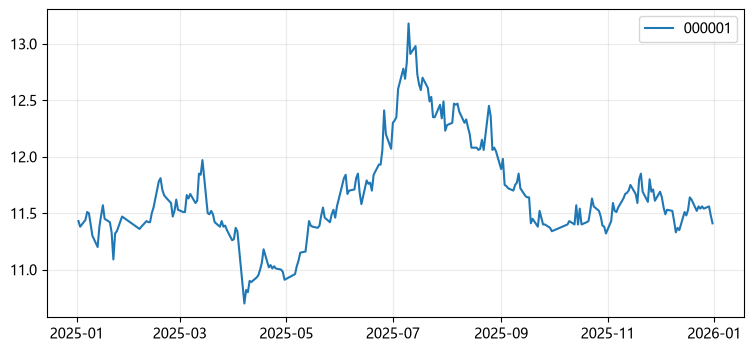

In [6]:
fig, ax = plt.subplots()
ax.plot(stock.index, stock["Clsprc"], label=TARGET)
# ax.set(title=..., xlabel=..., ylabel=...)
ax.legend()
plt.show()

**我的解释：**（填写预测、实际结果或原因。）

<details><summary>参考答案（先自己动手）</summary>

```python
fig, ax = plt.subplots()
ax.plot(stock.index, stock["Clsprc"], label=TARGET)
ax.set(title=f"{TARGET}｜2025年未复权收盘价", xlabel="交易日期", ylabel="收盘价（元）")
ax.legend()
fig.tight_layout()
plt.show()
```

横轴是交易日期，纵轴是价格（元）。不同股票价格高低不能直接用来比较投资收益。修改TARGET时还要重建stock，不能只修改图例。

</details>

## 练习5｜保存并读回CSV

将当前stock的3月记录保存到outputs，再读回。解释reset_index、index=False和dtype的作用。

In [7]:
# march = stock.loc["2025-03"].reset_index()
# march.to_csv(OUTPUTS / "week06_march.csv", index=False)
# 请读回并检查列名和股票代码

**我的解释：**（填写预测、实际结果或原因。）

<details><summary>参考答案（先自己动手）</summary>

```python
march = stock.loc["2025-03"].reset_index()
march.to_csv(OUTPUTS / "week06_march.csv", index=False, encoding="utf-8-sig")
loaded = pd.read_csv(OUTPUTS / "week06_march.csv", dtype={"Stkcd": str}, parse_dates=["Trddt"])
print(loaded.columns.tolist())
display(loaded.head())
```

reset_index把日期索引恢复成列；index=False不额外保存行号；dtype保留股票代码前导零。CSV本身不保存pandas类型。

</details>

## 提交与自查

- 一张带标题和单位的价格图、一份月份CSV。
- 写三句观察，区分价格、成交股数与成交金额。

提交本周 Notebook，保留你的代码、输出和文字解释。重启内核并按顺序运行一次；不要只提交截图。如使用AI辅助，请注明用在哪一题，并确保能解释关键行、现场修改一个参数。